# ExpTM — fresh training from the author Colab workflow

Run in a **fresh ExpTM kernel**, in order. This is a separate training run; no public checkpoint is loaded.

The workflow is adapted from the [author Colab](https://colab.research.google.com/drive/1Q5-LyumxZfZc6aHt71ZKOsGWfjrGEEzV) using the lattice-gas source at commit `bc55961331ff94a48e51974d9f537319ace96e9c` of [ExpTM](https://github.com/tiwarylab/ExpTM). Bundled author Python files are unmodified. The changes are portable paths, dynamic label counts, seeds, logging, and the author's suggested lower training budget of **5 epochs**.

**Scope:** one fresh model, supplied 10,000 training configurations, then 64 generated samples at each of three controls. This is an implementation/reproduction pilot, not a qualified Figure 2 reproduction or a stationary-phase result. No full heatmap or new MCMC simulation is included.

First run **Cells 1–3**. Cell 4 starts training; Cell 5 starts sampling. Keep the computer awake while they run.

Training success here means finite losses and five saved checkpoints; it does not establish physical accuracy. Density differences are reported without a post-hoc PASS threshold. Endpoint comparisons reuse training data; no independent midpoint reference is supplied. Stop on errors/non-finite values and retain the run. Do not extend epochs or change seeds based on the result in this run.

## Cell 1 — locate files and check the selected environment

Keep this notebook, `data/`, `author_training_source/`, and `training_manifest.json` together. If a dependency is missing, select your existing ExpTM environment before installing anything. `DEVICE_REQUEST="auto"` uses the author's CUDA-if-available/CPU-otherwise behavior; Mac runs on CPU. Set it to `"cpu"` **before starting** if you intentionally want CPU.

In [1]:
from pathlib import Path
import sys, json, hashlib, random, time, uuid, platform, importlib.util
from datetime import datetime, timezone

candidates = [Path.cwd(), Path.cwd()/"ExpTM_Fresh_Training",
              Path.cwd()/"exptm"/"ExpTM_Fresh_Training"]
ROOT = next((p.resolve() for p in candidates if (p/"training_manifest.json").is_file()), None)
assert ROOT is not None, "Open this notebook from the extracted ExpTM_Fresh_Training folder."
missing = [m for m in ["numpy", "torch", "matplotlib", "einops", "yaml"]
           if importlib.util.find_spec(m) is None]
assert not missing, f"Missing packages: {missing}. Select the ExpTM kernel."

import numpy as np
import torch
import matplotlib.pyplot as plt

DEVICE_REQUEST = "auto"  # Set before creating the model: "auto" or "cpu".
assert DEVICE_REQUEST in {"auto", "cpu"}
if DEVICE_REQUEST == "cpu":
    # Select the CPU default used by the author without modifying author source.
    # CUDA visibility must be configured before torch is imported; use the
    # backbone override in Cell 3 instead.
    pass

manifest = json.loads((ROOT/"training_manifest.json").read_text())
for relative, expected in manifest["sha256"].items():
    assert hashlib.sha256((ROOT/relative).read_bytes()).hexdigest() == expected, relative

SOURCE = ROOT/"author_training_source"
for name, module in list(sys.modules.items()):
    if name == "tm" or name.startswith("tm."):
        filename = getattr(module, "__file__", None)
        assert filename and SOURCE in Path(filename).resolve().parents, (
            "A different tm package is already loaded. Restart this kernel."
        )
sys.path.insert(0, str(SOURCE))
from tm.core.prior import GlobalEquilibriumHarmonicPrior
from tm.core.backbone import ConvBackbone
from tm.core.diffusion_model import DiffusionTrainer, SteeredDiffusionSampler
from tm.core.diffusion_process import VPDiffusion
from tm.architectures.unet_2d_mid_attn import Unet2D
from tm.core.loader import Loader

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Author source:", SOURCE)
print("All bundled file hashes verified.")


Python: c:\Users\user\AppData\Local\Python\pythoncore-3.14-64\python.exe
PyTorch: 2.14.1+cpu
CUDA available: False
Author source: C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\author_training_source
All bundled file hashes verified.


## Cell 2 — construct the three training channels

Channel 0 is the lattice coordinate (−1/+1); channel 1 is the prior variance control (1); channel 2 is the prior mean control (−1 or +1). These code controls are not automatically physical temperature or chemical potential. The author identifies the supplied physical training anchors as T=7, μ=−16 and μ=0.

This cell uses the actual number of samples instead of the stale 20,000-sample labels in the Colab. It never modifies the original arrays.

In [2]:
low = np.load(ROOT/"data/LowMuT7.npy", allow_pickle=False)
high = np.load(ROOT/"data/HighMuT7.npy", allow_pickle=False)
assert low.shape == high.shape == (5000, 2, 20, 20)
coords = np.concatenate([low[:, 0], high[:, 0]], axis=0)
assert np.isin(coords, [-1, 1]).all()
n_low, n_high = len(low), len(high)
pressures = np.concatenate([-np.ones(n_low), np.ones(n_high)]).astype(np.float32)
temperatures = np.ones(len(coords), dtype=np.float32)
training_data = np.empty((len(coords), 3, 20, 20), dtype=np.float32)
training_data[:, 0] = coords
training_data[:, 1] = temperatures[:, None, None]
training_data[:, 2] = pressures[:, None, None]
assert np.isfinite(training_data).all()
reference_density = {
    -1.0: (low[:, 0] >= 0).mean(axis=(1, 2)),
     1.0: (high[:, 0] >= 0).mean(axis=(1, 2)),
}
print("Training shape:", training_data.shape)
print("Samples per anchor:", n_low, n_high)
for p, rho in reference_density.items():
    print(f"Supplied training anchor p={p:+.0f}: mean density={rho.mean():.7f}")


Training shape: (10000, 3, 20, 20)
Samples per anchor: 5000 5000
Supplied training anchor p=-1: mean density=0.0481045
Supplied training anchor p=+1: mean density=0.9515275


## Cell 3 — create a new model and a unique output directory

Fresh random weights, 3 channels, dim=32, dim_mults=(1,2,4), target spatial size=32, 100 diffusion steps, learning rate=0.001, smooth-L1 loss. We retain the Colab Loader defaults (including normal dequantization) and its backbone self-conditioning setup. Exact numeric repeatability across hardware/PyTorch versions is not assumed.

In [3]:
SEED = 2026110901
EPOCHS = 5
BATCH_SIZE = 64
SAMPLE_COUNT = 64
SAMPLE_BATCH = 16
torch.set_num_threads(4)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

RUN = ROOT/"runs"/(datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")+"_"+uuid.uuid4().hex[:8])
RUN.mkdir(parents=True, exist_ok=False)
train_loader = Loader(data=training_data, pressures=pressures[:, None],
                      temperatures=temperatures[:, None], control_dims=(1, 3))
assert torch.isfinite(train_loader.data).all()
prior = GlobalEquilibriumHarmonicPrior(shape=train_loader.data.shape,
        channels_info={"coordinate": [0], "fluctuation": [1], "mean": [2]})
model = Unet2D(dim=32, dim_mults=(1, 2, 4), resnet_block_groups=8, channels=3)
backbone = ConvBackbone(model=model, data_shape=train_loader.data_dim,
        target_shape=32, num_dims=4, lr=1e-3, eval_mode="train", self_condition=True)
if DEVICE_REQUEST == "cpu":
    backbone.device = "cpu"
    backbone.model.to("cpu")
diffusion = VPDiffusion(num_diffusion_timesteps=100)

class CheckedTrainer(DiffusionTrainer):
    # Identical loss; only stop rather than updating on a non-finite value.
    def loss_function(self, e, e_pred, weight, loss_type="l2"):
        loss = super().loss_function(e, e_pred, weight, loss_type)
        if not torch.isfinite(loss).all():
            raise FloatingPointError("Non-finite training loss; run stopped.")
        return loss

trainer = CheckedTrainer(diffusion, backbone, train_loader, prior,
                         model_dir=str(RUN/"models"), pred_type="noise")
config = dict(seed=SEED, epochs=EPOCHS, batch_size=BATCH_SIZE, learning_rate=1e-3,
              loss="smooth_l1", diffusion_steps=100, training_shape=list(training_data.shape),
              temperature_control=1.0, mean_controls=[-1.0, 1.0],
              sampling_controls=[-1.0, 0.0, 1.0], sampling_count=SAMPLE_COUNT,
              sampling_batch=SAMPLE_BATCH, gamma=1.0, eta=1.0,
              device=backbone.device, device_request=DEVICE_REQUEST,
              torch_version=str(torch.__version__), numpy_version=np.__version__,
              python=sys.version, platform=platform.platform(),
              author_commit=manifest["commit"], public_checkpoint_loaded=False,
              source_and_data_sha256=manifest["sha256"],
              sampling_backbone_eval_mode="train (retained from author Colab)",
              interpretation="Implementation pilot; no scientific accuracy PASS threshold.")
(RUN/"config.json").write_text(json.dumps(config, indent=2))
TRAINING_STARTED = False
TRAINING_FINISHED = False
print("Device:", backbone.device)
print("Fresh model parameters:", sum(p.numel() for p in model.parameters()))
print("Output directory:", RUN)
print("Ready. The next cell starts 5 epochs; this cell has not trained anything.")


C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\author_training_source\tm\core\loader.py:304: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\python_variable_indexing.cpp:362.)
  self.unstd_control = self.data[self.control_slice][self.batch_slice]
C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\author_training_source\tm\core\loader.py:305: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will res

Device: cpu
Fresh model parameters: 3808739
Output directory: C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\runs\20261109T222137Z_be6572e7
Ready. The next cell starts 5 epochs; this cell has not trained anything.


## Cell 4 — TRAIN (5 epochs)

Run this cell once. It prints batch losses every 25 steps, saves each epoch, and estimates remaining time after each epoch. The estimate is local to your machine. Epoch checkpoint names use the author's zero-based numbering (`model_0.pt` through `model_4.pt`).

If interrupted, completed checkpoints remain. Do not rerun this cell to resume: that could change the experiment. Keep the folder and use the last completed checkpoint for a separately specified continuation if needed. An error, NaN, or OOM is a recorded technical failure, not a reason to silently change batch size or controls.

step: 0, loss 0.589
step: 25, loss 0.143
step: 50, loss 0.081
step: 75, loss 0.068
step: 100, loss 0.054
step: 125, loss 0.062
step: 150, loss 0.046
epoch: 0 | train loss: 0.103
Finished 1/5; elapsed 1.9 min; estimated remaining 7.7 min
step: 0, loss 0.043
step: 25, loss 0.044
step: 50, loss 0.035
step: 75, loss 0.039
step: 100, loss 0.034
step: 125, loss 0.037
step: 150, loss 0.027
epoch: 1 | train loss: 0.036
Finished 2/5; elapsed 3.9 min; estimated remaining 5.8 min
step: 0, loss 0.024
step: 25, loss 0.029
step: 50, loss 0.024
step: 75, loss 0.025
step: 100, loss 0.026
step: 125, loss 0.029
step: 150, loss 0.035
epoch: 2 | train loss: 0.030
Finished 3/5; elapsed 5.8 min; estimated remaining 3.9 min
step: 0, loss 0.035
step: 25, loss 0.020
step: 50, loss 0.023
step: 75, loss 0.020
step: 100, loss 0.028
step: 125, loss 0.021
step: 150, loss 0.023
epoch: 3 | train loss: 0.026
Finished 4/5; elapsed 7.8 min; estimated remaining 1.9 min
step: 0, loss 0.026
step: 25, loss 0.033
step: 50, l

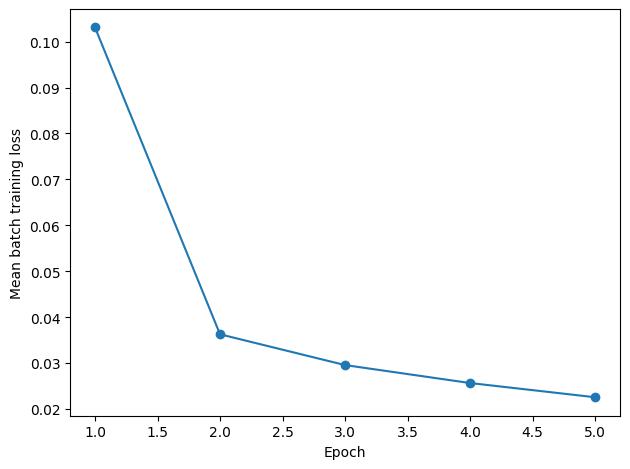

Training finished. Checkpoints are saved in: C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\runs\20261109T222137Z_be6572e7\models


In [4]:
assert not TRAINING_STARTED, "Training already started in this run. Keep its files; do not rerun this cell."
assert not list((RUN/"models").glob("*.pt")), "Existing checkpoints found."
TRAINING_STARTED = True
history = []
started = time.perf_counter()
try:
    for epoch in range(EPOCHS):
        epoch_started = time.perf_counter()
        backbone.start_epoch = epoch
        backbone.model.train()
        trainer.train(1, loss_type="smooth_l1", batch_size=BATCH_SIZE, print_freq=25)
        loss_value = float(trainer.train_losses[-1])
        assert np.isfinite(loss_value)
        checkpoint = RUN/"models"/f"model_{epoch}.pt"
        assert checkpoint.is_file()
        history.append(dict(epoch=epoch+1, mean_batch_loss=loss_value,
                            seconds=time.perf_counter()-epoch_started,
                            checkpoint=checkpoint.name))
        (RUN/"training_history.json").write_text(json.dumps(history, indent=2))
        # Supplement the author's model/optimizer checkpoint with RNG state.
        torch.save(dict(python=random.getstate(), numpy=np.random.get_state(),
                        torch_cpu=torch.get_rng_state(),
                        torch_cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else []),
                   RUN/"models"/f"rng_{epoch}.pt")
        elapsed = time.perf_counter()-started
        remaining = elapsed/(epoch+1)*(EPOCHS-epoch-1)
        print(f"Finished {epoch+1}/{EPOCHS}; elapsed {elapsed/60:.1f} min; estimated remaining {remaining/60:.1f} min", flush=True)
    TRAINING_FINISHED = True
    (RUN/"training_status.json").write_text(json.dumps(dict(status="completed",
        epochs_completed=len(history), seconds=time.perf_counter()-started,
        scientific_accuracy_validated=False), indent=2))
except BaseException as exc:
    (RUN/"training_status.json").write_text(json.dumps(dict(status="interrupted_or_failed",
        epochs_completed=len(history), error=repr(exc),
        seconds=time.perf_counter()-started), indent=2))
    raise

plt.plot([r["epoch"] for r in history], [r["mean_batch_loss"] for r in history], "o-")
plt.xlabel("Epoch"); plt.ylabel("Mean batch training loss")
plt.tight_layout(); plt.savefig(RUN/"training_loss.png", dpi=150); plt.show()
print("Training finished. Checkpoints are saved in:", RUN/"models")


## Cell 5 — sample from YOUR trained model

Optional after training: generate 64 samples at each mean control −1, 0, +1 at variance control 1. This uses the final (fifth-epoch) model, without selecting a checkpoint by its output. Original float coordinates and thresholded densities are saved separately.

The Colab leaves `backbone.eval_mode="train"` during sampling; that behavior is preserved and recorded here. We set the PyTorch model to eval mode, which is distinct from that author-specific flag. This architecture has no dropout/batch-normalization layers. No reverse-process formulas are changed.

{"mean_control": -1.0, "variance_control": 1.0, "seed": 2026111001, "n": 64, "density_mean": 0.0008593750000000001, "density_std": 0.0014919592689874145, "seconds": 37.90047230001073, "training_density_mean": 0.048104499999999994, "absolute_mean_density_gap": 0.04724512499999999}
{"mean_control": 0.0, "variance_control": 1.0, "seed": 2026111002, "n": 64, "density_mean": 0.5710546875, "density_std": 0.021127939297253116, "seconds": 39.12697870004922}
{"mean_control": 1.0, "variance_control": 1.0, "seed": 2026111003, "n": 64, "density_mean": 0.9977734375, "density_std": 0.002444510675058741, "seconds": 39.176078799995594, "training_density_mean": 0.9515275, "absolute_mean_density_gap": 0.046245937500000056}


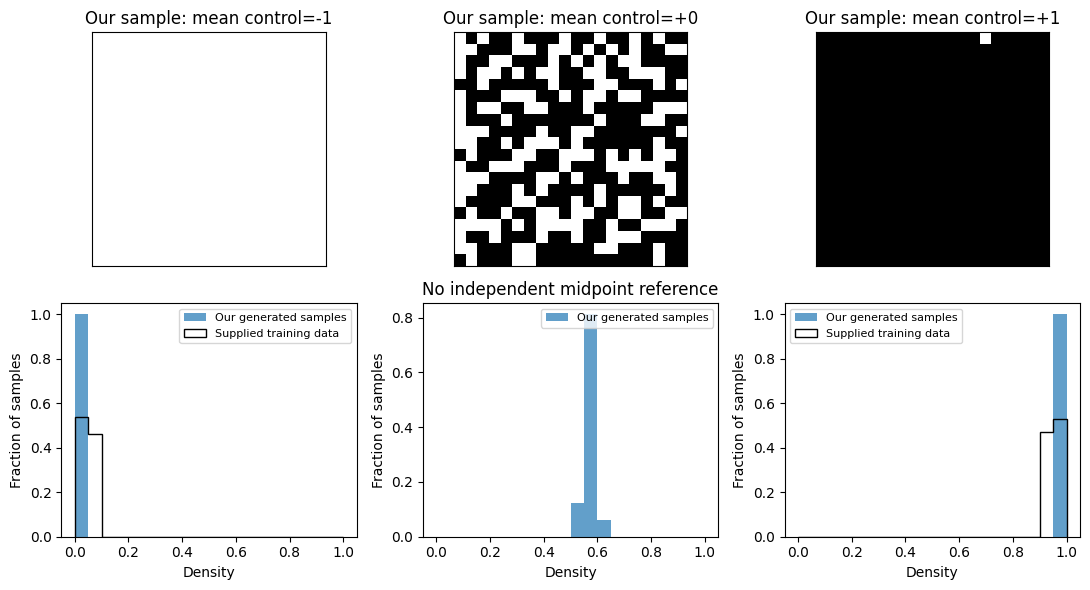

Pilot complete. Results: C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\runs\20261109T222137Z_be6572e7
This is not the full Figure 2 heatmap or independent physical validation.


In [5]:
assert TRAINING_FINISHED, "Complete Cell 4 first."
assert not (RUN/"sampling_started.json").exists(), "Sampling already started. Preserve this run."
(RUN/"sampling_started.json").write_text(json.dumps({"count_per_control":SAMPLE_COUNT}))
assert SAMPLE_COUNT % SAMPLE_BATCH == 0
backbone.model.eval()
sampler = SteeredDiffusionSampler(diffusion, backbone, train_loader, prior, pred_type="noise")
sample_rows = []
generated = {}
for index, p in enumerate([-1.0, 0.0, 1.0]):
    sample_seed = SEED + 100 + index
    random.seed(sample_seed); np.random.seed(sample_seed); torch.manual_seed(sample_seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(sample_seed)
    t0 = time.perf_counter()
    raw = sampler.sample_loop(num_samples=SAMPLE_COUNT, batch_size=SAMPLE_BATCH,
                              temperature=1.0, pressure=p, gamma=1, eta=1)
    raw = raw.detach().cpu().numpy()
    assert raw.shape == (SAMPLE_COUNT, 3, 20, 20), raw.shape
    assert np.isfinite(raw).all(), "Non-finite generated values; stop."
    np.save(RUN/f"samples_p{p:+.0f}.npy", raw)
    occupancy = (raw[:, 0] >= 0).astype(np.uint8)
    rho = occupancy.mean(axis=(1, 2))
    generated[p] = occupancy
    row = dict(mean_control=p, variance_control=1.0, seed=sample_seed,
               n=len(rho), density_mean=float(rho.mean()),
               density_std=float(rho.std(ddof=1)),
               seconds=time.perf_counter()-t0)
    if p in reference_density:
        row["training_density_mean"] = float(reference_density[p].mean())
        row["absolute_mean_density_gap"] = abs(row["density_mean"]-row["training_density_mean"])
    sample_rows.append(row)
    (RUN/"sample_summary.json").write_text(json.dumps(sample_rows, indent=2))
    print(json.dumps(row), flush=True)

fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for j, p in enumerate([-1.0, 0.0, 1.0]):
    axes[0, j].imshow(generated[p][0], cmap="binary", vmin=0, vmax=1)
    axes[0, j].set_title(f"Our sample: mean control={p:+.0f}")
    axes[0, j].set_xticks([]); axes[0, j].set_yticks([])
    rho = generated[p].mean(axis=(1, 2))
    bins = np.linspace(0, 1, 21)
    axes[1, j].hist(rho, bins=bins, weights=np.ones(len(rho))/len(rho),
                    alpha=.7, label="Our generated samples")
    if p in reference_density:
        ref = reference_density[p]
        axes[1, j].hist(ref, bins=bins, weights=np.ones(len(ref))/len(ref),
                        histtype="step", color="black", label="Supplied training data")
    else:
        axes[1, j].set_title("No independent midpoint reference")
    axes[1, j].set_xlabel("Density"); axes[1, j].set_ylabel("Fraction of samples")
    axes[1, j].legend(fontsize=8)
plt.tight_layout(); plt.savefig(RUN/"pilot_samples.png", dpi=160); plt.show()
print("Pilot complete. Results:", RUN)
print("This is not the full Figure 2 heatmap or independent physical validation.")


In [6]:
from zipfile import ZipFile, ZIP_DEFLATED

review_zip = RUN / "pilot_review.zip"

files = [
    "config.json",
    "training_history.json",
    "training_status.json",
    "sample_summary.json",
    "training_loss.png",
    "pilot_samples.png",
]
files += [p.name for p in RUN.glob("samples_p*.npy")]

with ZipFile(review_zip, "w", ZIP_DEFLATED) as z:
    for name in files:
        path = RUN / name
        if path.is_file():
            z.write(path, arcname=name)

print(review_zip)

C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\runs\20261109T222137Z_be6572e7\pilot_review.zip


In [7]:
from pathlib import Path
from datetime import datetime
import subprocess
import sys

project = Path(
    r"C:\Users\user\Documents\GitHub\active-matter-reproductions"
    r"\exptm\ExpTM_Fresh_Training"
)
script = project / "check_checkpoint.py"
checkpoint = (
    project / "runs" / "20261109T222137Z_be6572e7"
    / "models" / "model_4.pt"
)
output = project / "runs" / (
    "diagnostic_" + datetime.now().strftime("%Y%m%d_%H%M%S")
)

assert script.is_file(), f"Script not found: {script}"
assert checkpoint.is_file(), f"Checkpoint not found: {checkpoint}"

subprocess.run(
    [
        sys.executable, str(script),
        "--project", str(project),
        "--checkpoint", str(checkpoint),
        "--output", str(output),
    ],
    check=True,
)

print("Results saved to:", output)

Results saved to: C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\runs\diagnostic_20261110_004901


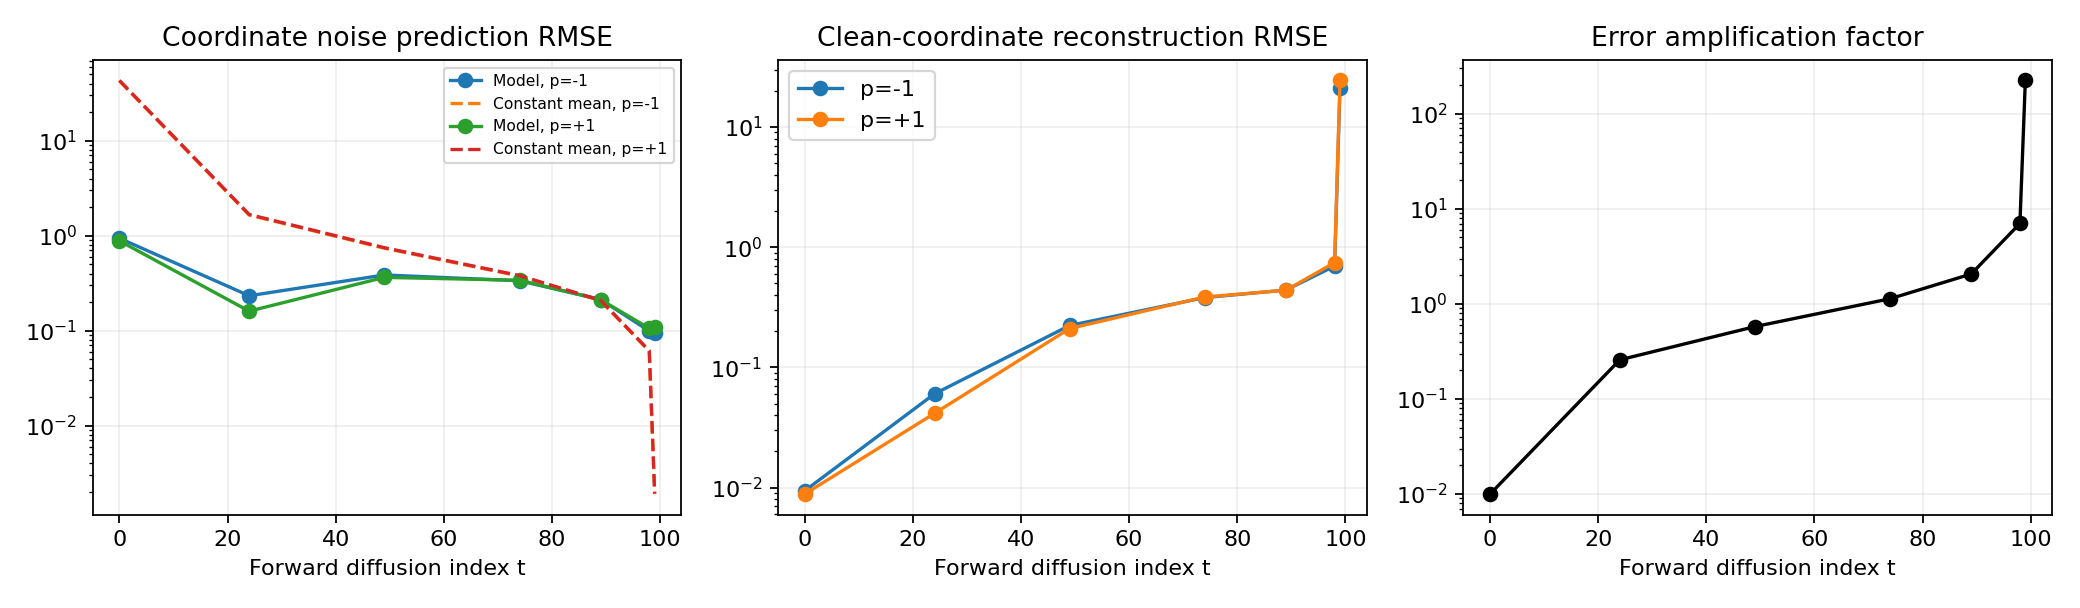

In [8]:
from IPython.display import Image, display

display(Image(filename=str(output / "checkpoint_diagnostic.png")))

## What to bring back

Show `training_loss.png`, `pilot_samples.png`, and `sample_summary.json`, plus any errors. Keep the entire run folder and configuration. Report density mismatch even if images look plausible. Low training loss alone is not a physical validation. Review the pilot before authorizing a larger grid; physical-axis mapping and reference-grid correspondence remain unresolved.

**Validation of this delivery:** all notebook cells passed Python syntax checks; bundled author files were checked against their pinned Git blobs; data shapes, labels and endpoint means were executed and checked. This workspace has no PyTorch installed, so model construction, training, and sampling have **not** been executed here. Outputs are intentionally empty.